# DL Complexity: примеры и эталоны

Общий API и основные методы. Подробно: blockwise, online, replay и калибровка.
В таблицах указаны **результат, эталон и абсолютная ошибка**. Для обучаемой MLP
вместо неизвестного точного значения используются два явно заданных ориентира.

CPU, синтетические данные, без загрузок. Таблицы и графики сохранены в ноутбуке.
Запуск из корня проекта:

```bash
python -m pip install -e ".[demo]"
python -m jupyterlab examples/demo.ipynb
```

Выберите Python этого окружения и выполните **Restart Kernel and Run All Cells**.


In [1]:
import math
import platform
import sys
from dataclasses import asdict
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import torch
from IPython.display import Markdown, display
from torch import nn
from torch.distributions import MultivariateNormal, Normal, kl_divergence
from torch.nn import functional as F

# Поддерживаем запуск из корня проекта и из examples/.
ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "src" / "dl_complexity").is_dir()),
    None,
)
if ROOT is None:
    raise RuntimeError("Откройте ноутбук из checkout dl-complexity или examples/.")
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "examples"))

from dl_complexity import ComplexitySuite, DataSource, ModelContext, Provenance
from dl_complexity.bayesian import (
    KFACLaplace, TemperedLikelihood, VariationalCode, VariationalTerms, WBIC,
    prepare_gaussian_linear_kfac,
)
from dl_complexity.bounds import AroraCompressionBound, prepare_arora_projection
from dl_complexity.coding import (
    BlockwisePrequential, OnlinePrequential, ReplayPrequential, TemperatureScaler,
    TwoPartMDL, prepare_blockwise, prepare_online, prepare_replay, prepare_two_part,
)
from dl_complexity.compression import (
    AroraMatrixProject, BinaryModelCodec, LowRankApproximation,
    MagnitudePruning, UniformQuantization,
)
from dl_complexity.criteria import AIC, BIC, HQIC, WAIC, PosteriorLogLikelihood
from dl_complexity.diagnostics import WeightStatistics
from dl_complexity.integrations.torch import CategoricalLikelihood, GaussianLikelihood
from prequential_demo import (
    DemoConfig, block_boundaries, fit, make_data, make_learner, predict_logits,
)

torch.set_num_threads(1)
DTYPE = torch.float64


def table(headers, rows):
    """Маленькая Markdown-таблица без зависимости от pandas."""
    display(Markdown(
        "| " + " | ".join(headers) + " |\n"
        + "| " + " | ".join("---" for _ in headers) + " |\n"
        + "\n".join("| " + " | ".join(map(str, row)) + " |" for row in rows)
    ))


print(f"Python {platform.python_version()} | Torch {torch.__version__}")
print("device=cpu | dtype=float64 | threads=1")


Python 3.14.7 | Torch 2.14.1+cpu
device=cpu | dtype=float64 | threads=1


## 1. API и единицы

`ModelContext` — модель и likelihood; `DataSource` — данные.
`check` проверяет входы, `estimate` возвращает оценку. `inputs` принимает готовые
артефакты, `ComplexitySuite` объединяет вызовы.

| Методы | Результат | Единицы |
|---|---|---|
| AIC / BIC / HQIC / WAIC | Информационный критерий | `native_ic` |
| WBIC / Laplace | Приближение −log evidence | `nats` |
| Variational | Отрицательный ELBO | `nats` |
| Prequential / 2-part MDL | Длина кода | `bits` / `nats` |
| Arora | Граница риска | `probability` |
| WeightStatistics | Нормы и разреженность | Именованные величины |

Значения разных семейств не образуют общую шкалу сложности.


### AIC, BIC, HQIC: точное MLE

$y=(1,2,4,5)$, $y_i\sim N(\mu,1)$: $\hat\mu=3$, $n=4$, $k=1$.
`Linear(1,1,bias=False)` на единичных входах задаёт среднее.

Эталоны: $AIC=-2\ell+2k$, $BIC=-2\ell+k\ln n$,
$HQIC=-2\ell+2k\ln\ln n$, где $\ell=-2\ln(2\pi)-5$.
Готовность входов не доказывает выполнение предпосылок критерия.


In [2]:
gx = torch.ones(4, 1, dtype=DTYPE)
gy = torch.tensor([1., 2., 4., 5.], dtype=DTYPE)[:, None]
gaussian_model = nn.Linear(1, 1, bias=False, dtype=DTYPE)
with torch.no_grad():
    gaussian_model.weight.fill_(gy.mean())
gaussian_context = ModelContext(
    gaussian_model, likelihood=GaussianLikelihood(sigma=1.), state_id="gaussian-mle"
)
gaussian_data = DataSource.from_tensors(gx, gy, data_id="four-gaussian-values")
suite = ComplexitySuite({"AIC": AIC(), "BIC": BIC(), "HQIC": HQIC(), "WAIC": WAIC()},
                        errors="collect")
outcomes = suite.estimate(context=gaussian_context, data=gaussian_data)
ll_reference = -2 * math.log(2 * math.pi) - 5
ic_references = {
    "AIC": -2 * ll_reference + 2,
    "BIC": -2 * ll_reference + math.log(4),
    "HQIC": -2 * ll_reference + 2 * math.log(math.log(4)),
}
rows = []
for name, reference in ic_references.items():
    outcome = outcomes[name]
    if outcome.error is not None:
        raise outcome.error
    value = outcome.result.primary.value.item()
    assert math.isclose(value, reference, rel_tol=0, abs_tol=1e-12)
    rows.append((name, f"{value:.6f}", f"{reference:.6f}", f"{abs(value-reference):.2e}"))
table(["Метод", "Получено", "Точно", "Абс. ошибка"], rows)
print("Единицы: native_ic. WAIC без posterior:", outcomes["WAIC"].requirements.status.value)


| Метод | Получено | Точно | Абс. ошибка |
| --- | --- | --- | --- |
| AIC | 19.351508 | 19.351508 | 0.00e+00 |
| BIC | 18.737803 | 18.737803 | 0.00e+00 |
| HQIC | 18.004777 | 18.004777 | 0.00e+00 |

Единицы: native_ic. WAIC без posterior: MISSING_INPUTS


In [3]:
bic_result = outcomes["BIC"].result
table(["Компонента BIC", "Значение", "Единицы", "Нормировка"], [
    (name, f"{q.value.item():.6f}", q.unit, q.normalization)
    for name, q in bic_result.quantities.items()
])
print("Вид результата:", bic_result.kind)
print("Первое допущение:", bic_result.assumptions[0])


| Компонента BIC | Значение | Единицы | Нормировка |
| --- | --- | --- | --- |
| bic | 18.737803 | native_ic | total |
| deviance | 17.351508 | native_ic | total |
| penalty | 1.386294 | native_ic | total |

Вид результата: information_criterion
Первое допущение: Regular finite-dimensional MLE asymptotics; not certified for arbitrary neural weights.


## 2. Байесовские оценки

Для той же модели задаём prior $\mu\sim N(0,1/\alpha)$, $\alpha=1$.
Posterior: $v=(\alpha+n)^{-1}$, $m=v\sum y_i$.
WBIC использует $\beta=1/\ln n$ и отдельный tempered posterior:
$v_\beta=(\alpha+\beta n)^{-1}$, $m_\beta=v_\beta\beta\sum y_i$.

Выборки независимы, seed фиксирован. Эталоны WAIC/WBIC рассчитаны аналитически;
отклонение от них — погрешность Монте-Карло. Для WAIC отдельно проверяется
точность вычисления на той же конечной матрице likelihood.


In [4]:
n_gaussian, alpha, draws = len(gy), 1., 8192
observed = gy[:, 0]
variance = 1 / (alpha + n_gaussian)
mean = variance * observed.sum()
beta = 1 / math.log(n_gaussian)
variance_beta = 1 / (alpha + beta * n_gaussian)
mean_beta = variance_beta * beta * observed.sum()
generator = torch.Generator().manual_seed(2026)
mu = mean + math.sqrt(variance) * torch.randn(draws, generator=generator, dtype=DTYPE)
mu_beta = mean_beta + math.sqrt(variance_beta) * torch.randn(
    draws, generator=generator, dtype=DTYPE
)
pointwise = Normal(mu[:, None], 1.).log_prob(observed[None, :])
tempered_total = Normal(mu_beta[:, None], 1.).log_prob(observed[None, :]).sum(1)
waic_result = WAIC().estimate(inputs=PosteriorLogLikelihood(pointwise))
wbic_result = WBIC().estimate(inputs=TemperedLikelihood(tempered_total, n_gaussian, beta))

# Аналитический WAIC: log E[p(y_i|mu)] и Var[log p(y_i|mu)].
residual2 = (observed - mean).square()
exact_lppd = Normal(mean, math.sqrt(1 + variance)).log_prob(observed).sum()
exact_p_waic = (variance * residual2 + variance ** 2 / 2).sum()
exact_waic = -2 * (exact_lppd - exact_p_waic)
expected_wbic = 0.5 * (
    n_gaussian * math.log(2 * math.pi)
    + ((observed - mean_beta).square() + variance_beta).sum().item()
)
table(["Метод", "Получено (MC)", "Аналитически", "Ошибка MC"], [
    (r.method, f"{r.primary.value.item():.6f}", f"{float(ref):.6f}",
     f"{abs(r.primary.value.item()-float(ref)):.6f}")
    for r, ref in [(waic_result, exact_waic), (wbic_result, expected_wbic)]
])
# Независимая арифметика WAIC на конечной матрице: не MC-эталон posterior.
centered = pointwise - pointwise.mean(0)
finite_waic = -2 * (
    pointwise.exp().mean(0).log().sum()
    - (centered.square().sum(0) / (draws - 1)).sum()
)
torch.testing.assert_close(waic_result.primary.value, finite_waic, rtol=0, atol=1e-12)
print(f"WAIC: native_ic; WBIC: nats; выборок: {draws}.")
print(f"WAIC, ошибка редукции матрицы: {abs(waic_result.primary.value.item()-finite_waic.item()):.2e}")


| Метод | Получено (MC) | Аналитически | Ошибка MC |
| --- | --- | --- | --- |
| WAIC | 22.285993 | 22.350128 | 0.064134 |
| WBIC | 10.374735 | 10.382852 | 0.008116 |

WAIC: native_ic; WBIC: nats; выборок: 8192.
WAIC, ошибка редукции матрицы: 3.55e-15


### Variational и Laplace: точное evidence

При $q=p(\mu\mid y)$ отрицательный ELBO равен $-\log p(y)$.
KFAC-Laplace для одного Gaussian Linear в MAP также точен.
Независимый эталон: $y\sim N(0,I+\mathbf1\mathbf1^T/\alpha)$.
Для произвольной нейросети эти равенства не гарантируются.


In [5]:
q = Normal(mean, math.sqrt(variance))
prior = Normal(torch.tensor(0., dtype=DTYPE), 1 / math.sqrt(alpha))
expected_nll = 0.5 * (
    n_gaussian * math.log(2 * math.pi)
    + ((observed - mean).square() + variance).sum()
)
vi_result = VariationalCode().estimate(inputs=VariationalTerms(
    expected_nll=expected_nll, kl_divergence=kl_divergence(q, prior), n=n_gaussian,
))
map_model = nn.Linear(1, 1, bias=False, dtype=DTYPE)
with torch.no_grad():
    map_model.weight.fill_(mean)
factors = prepare_gaussian_linear_kfac(
    map_model, gx, gy, noise_std=1., prior_precision=alpha,
)
laplace_result = KFACLaplace().estimate(inputs=factors)
# Независимый эталон: интегрирование mu даёт y ~ N(0, I + 11^T/alpha).
covariance = torch.eye(n_gaussian, dtype=DTYPE) + gx @ gx.T / alpha
exact_evidence_nll = -MultivariateNormal(
    torch.zeros(n_gaussian, dtype=DTYPE), covariance_matrix=covariance
).log_prob(observed)
for result in (vi_result, laplace_result):
    torch.testing.assert_close(result.primary.value, exact_evidence_nll, rtol=0, atol=1e-10)

table(["Метод", "Получено, nats", "Точно, nats", "Абс. ошибка"], [
    (r.method, f"{r.primary.value.item():.6f}", f"{exact_evidence_nll.item():.6f}",
     f"{abs(r.primary.value.item()-exact_evidence_nll.item()):.2e}")
    for r in (vi_result, laplace_result)
])


| Метод | Получено, nats | Точно, nats | Абс. ошибка |
| --- | --- | --- | --- |
| VariationalCode | 13.080473 | 13.080473 | 1.78e-15 |
| KFACLaplace | 13.080473 | 13.080473 | 0.00e+00 |

## 3. Prequential: точные малые примеры

Метка оплачивается **до** обучения на ней. Для `0,1,1,0` online-предиктор
Beta(1,1) даёт вероятности $1/2,1/3,1/2,2/5$: длина $\log_2 30$ битов.
В blockwise `[1,2,4]` вероятности фиксируются на блоке: $\log_2 24$ битов.
Replay-счётчик учитывает каждый индекс один раз, поэтому его эталон также $\log_2 30$.
Это учебные предикторы; далее будет обучаемая MLP.


In [6]:
toy_x = torch.arange(4, dtype=DTYPE)[:, None]
toy_y = torch.tensor([0, 1, 1, 0])
events = []


def frequency_predict(counts, batch):
    events.append(("predict", int(batch[0, 0])))
    return counts.log().expand(len(batch), -1)


def frequency_update(counts, batch, labels):
    events.append(("update", int(batch[0, 0])))
    counts.add_(torch.bincount(labels, minlength=2))


toy_ledger = prepare_online(
    toy_x, toy_y, model_factory=lambda: torch.ones(2, dtype=DTYPE),
    predict_logits=frequency_predict, update=frequency_update,
    n_classes=2, batch_size=1,
)
toy_result = OnlinePrequential(unit="bits").estimate(inputs=toy_ledger)
assert math.isclose(toy_result.primary.value.item(), math.log2(30), abs_tol=1e-12)
assert events == [event for i in range(4) for event in (("predict", i), ("update", i))]

def block_train(state, prefix_x, prefix_y):
    state["counts"] = torch.bincount(prefix_y, minlength=2).to(DTYPE) + 1


block_ledger = prepare_blockwise(
    toy_x, toy_y, boundaries=[1, 2, 4], model_factory=dict, train=block_train,
    predict_logits=lambda state, batch: state["counts"].log().expand(len(batch), -1),
    n_classes=2,
)


def replay_predict(state, batch):
    counts = torch.ones(2, dtype=DTYPE)
    for label in state.values():
        counts[label] += 1
    return counts.log().expand(len(batch), -1)


def replay_update_unique(state, new_x, new_y, replay_x, replay_y):
    for batch, labels in ((new_x, new_y), (replay_x, replay_y)):
        for index, label in zip(batch[:, 0].tolist(), labels.tolist()):
            state[int(index)] = label  # Повтор индекса не добавляет новое наблюдение.


toy_replay = prepare_replay(
    toy_x, toy_y, model_factory=dict, predict_logits=replay_predict,
    update=replay_update_unique, n_classes=2, batch_size=1, replay_size=2, seed=9,
)
toy_cases = [
    ("Blockwise", BlockwisePrequential(unit="bits").estimate(inputs=block_ledger), math.log2(24)),
    ("Online", toy_result, math.log2(30)),
    ("Replay", ReplayPrequential(unit="bits").estimate(inputs=toy_replay), math.log2(30)),
]
for _, result, reference in toy_cases:
    assert math.isclose(result.primary.value.item(), reference, rel_tol=0, abs_tol=1e-12)
table(["Протокол", "Получено, бит", "Точно, бит", "Абс. ошибка"], [
    (name, f"{r.primary.value.item():.6f}", f"{ref:.6f}", f"{abs(r.primary.value.item()-ref):.2e}")
    for name, r, ref in toy_cases
])
print("Порядок online:", " → ".join(event[0] for event in events[:4]), "…")


| Протокол | Получено, бит | Точно, бит | Абс. ошибка |
| --- | --- | --- | --- |
| Blockwise | 4.584963 | 4.584963 | 0.00e+00 |
| Online | 4.906891 | 4.906891 | 0.00e+00 |
| Replay | 4.906891 | 4.906891 | 0.00e+00 |

Порядок online: predict → update → predict → update …


## 4. Prequential на MLP

Сеть `2 → 8 → 2`, `tanh`, Adam. Данные:
$p(y=1\mid x)=\sigma(2.5x_1-1.5x_2)$. Все запуски используют одни данные и начальные веса.

| Протокол | Обновление после оплаты блока |
|---|---|
| Blockwise | Новая сеть на прошлом префиксе |
| Online | Та же сеть на новом блоке |
| Replay | Та же сеть: новый блок + раскрытые примеры |

Ориентиры: **равномерный код** — ровно $n$ битов; **код генератора** —
$-\sum\log_2 p_{true}(y_i\mid x_i)$. Генератор знает истинные вероятности:
это ориентир, а не гарантированная нижняя граница на данной выборке.


{'n': 192, 'seed': 7, 'initial_count': 16, 'batch_size': 16, 'train_steps': 80, 'update_steps': 10, 'replay_size': 32, 'calibration_steps': 15, 'learning_rate': 0.03}
Границы blockwise: [16, 32, 64, 128, 192]


| Ориентир | Длина, бит |
| --- | --- |
| Равномерный | 192.000000 |
| Известный генератор | 96.856184 |

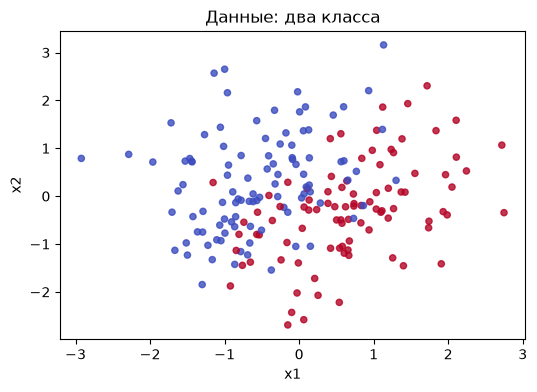

In [7]:
config = DemoConfig()
x, y = make_data(config)
boundaries = block_boundaries(config.n, config.initial_count)
print(asdict(config))
print("Границы blockwise:", boundaries)

true_logits = 2.5 * x[:, 0] - 1.5 * x[:, 1]
generator_costs = F.binary_cross_entropy_with_logits(true_logits, y.to(DTYPE), reduction="none") / math.log(2)
generator_bits = generator_costs.sum().item()
table(["Ориентир", "Длина, бит"], [
    ("Равномерный", f"{config.n:.6f}"), ("Известный генератор", f"{generator_bits:.6f}")
])
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(x[:, 0].numpy(), x[:, 1].numpy(), c=y.numpy(), cmap="coolwarm", s=20, alpha=0.8)
ax.set(xlabel="x1", ylabel="x2", title="Данные: два класса")
plt.show()


### Обучение и прогноз

Helpers из `prequential_demo.py` общие с CLI. Состояние хранит сеть и Adam.
Callbacks используют только переданные данные; порядок:
**прогноз → запись NLL → раскрытие меток → обновление**.


In [8]:
def factory():
    return make_learner(config)


def train_prefix(state, prefix_x, prefix_y):
    fit(state, prefix_x, prefix_y, config.train_steps)


def update_online(state, new_x, new_y):
    fit(state, new_x, new_y, config.update_steps)


def update_replay(state, new_x, new_y, replay_x, replay_y):
    fit(state, torch.cat((new_x, replay_x)), torch.cat((new_y, replay_y)),
        config.update_steps)


def new_calibrator():
    return TemperatureScaler(steps=config.calibration_steps)


def shared_arguments():
    return dict(
        model_factory=factory, predict_logits=predict_logits, n_classes=2,
        provenance=Provenance(
            state_id=f"mlp-initial-seed-{config.seed + 1}",
            data_id=f"synthetic-n{config.n}-seed-{config.seed}",
            likelihood_id="categorical",
        ),
    )


### Шесть запусков

Температура $T>0$ задаёт $p_T=\operatorname{softmax}(z/T)$.
В online/replay она обновляется после оплаты блока; в blockwise — на прошлом
обучающем префиксе. Каждый запуск получает новый калибратор.
`prepare_*` обучает и создаёт журнал, оценщик суммирует его.


In [9]:
estimators = {"blockwise": BlockwisePrequential, "online": OnlinePrequential,
              "replay": ReplayPrequential}
ledgers, results, durations = {}, {}, {}
for protocol, estimator in estimators.items():
    for calibrated in (False, True):
        key = (protocol, calibrated)
        started = perf_counter()
        if protocol == "blockwise":
            ledger = prepare_blockwise(
                x, y, boundaries=boundaries, train=train_prefix,
                calibrator_factory=new_calibrator if calibrated else None,
                **shared_arguments(),
            )
        else:
            stream = dict(
                batch_size=config.batch_size, initial_count=config.initial_count,
                calibrator=new_calibrator() if calibrated else None,
                **shared_arguments(),
            )
            if protocol == "online":
                ledger = prepare_online(x, y, update=update_online, **stream)
            else:
                ledger = prepare_replay(
                    x, y, update=update_replay, replay_size=config.replay_size,
                    seed=config.seed + 2, **stream,
                )
        method = estimator(unit="bits")
        assert method.check(inputs=ledger).ready
        ledgers[key] = ledger
        results[key] = method.estimate(inputs=ledger)
        durations[key] = perf_counter() - started


table(["Протокол", "T", "Получено, бит", "Равномерный", "Генератор", "Δ к генератору", "Секунды"], [
    (protocol, "обучен" if calibrated else "1", f"{r.primary.value.item():.4f}",
     f"{config.n:.4f}", f"{generator_bits:.4f}",
     f"{r.primary.value.item()-generator_bits:+.4f}", f"{durations[key]:.3f}")
    for key, r in results.items() for protocol, calibrated in [key]
])


| Протокол | T | Получено, бит | Равномерный | Генератор | Δ к генератору | Секунды |
| --- | --- | --- | --- | --- | --- | --- |
| blockwise | 1 | 129.9731 | 192.0000 | 96.8562 | +33.1169 | 0.651 |
| blockwise | обучен | 150.7168 | 192.0000 | 96.8562 | +53.8606 | 0.117 |
| online | 1 | 136.7170 | 192.0000 | 96.8562 | +39.8608 | 0.038 |
| online | обучен | 130.7332 | 192.0000 | 96.8562 | +33.8770 | 0.065 |
| replay | 1 | 119.5394 | 192.0000 | 96.8562 | +22.6832 | 0.040 |
| replay | обучен | 126.8715 | 192.0000 | 96.8562 | +30.0153 | 0.066 |

### Сравнение кодов

Все длины — в битах для одной последовательности. Меньше — лучше прогноз в этом
опыте. Бюджеты blockwise и online/replay различаются; секунды включают обучение.
Калибровка не обязана улучшать код. Одного seed недостаточно для общего вывода.


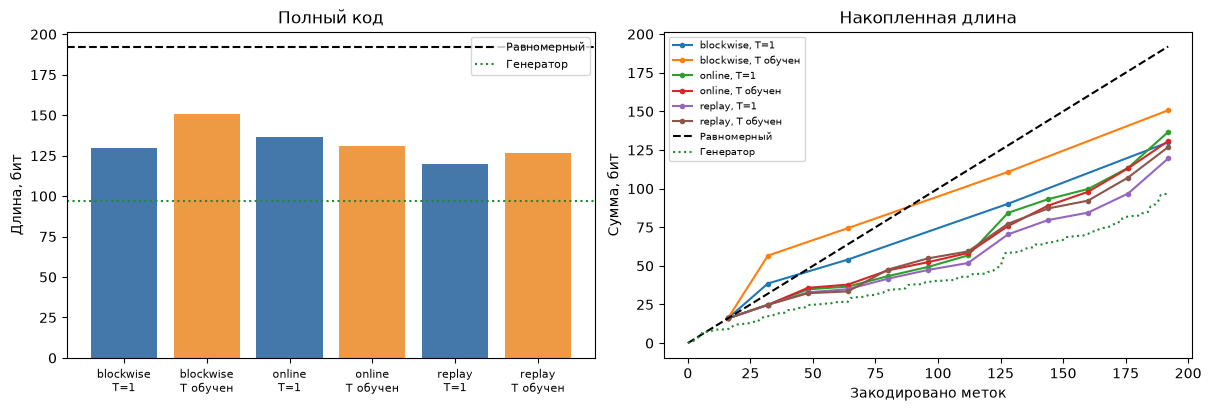

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
labels = [f"{p}\n{'T обучен' if c else 'T=1'}" for p, c in results]
values = [r.primary.value.item() for r in results.values()]
axes[0].bar(labels, values, color=["#4477aa" if not c else "#ee9944" for _, c in results])
axes[0].axhline(config.n, color="black", linestyle="--", label="Равномерный")
axes[0].axhline(generator_bits, color="#228833", linestyle=":", label="Генератор")
axes[0].set(ylabel="Длина, бит", title="Полный код")
axes[0].tick_params(axis="x", labelsize=8)
axes[0].legend(fontsize=8)
for (protocol, calibrated), ledger in ledgers.items():
    stops, cumulative = [ledger.initial_count], [float(ledger.initial_nll) / math.log(2)]
    for entry in ledger.entries:
        stops.append(entry.stop)
        cumulative.append(cumulative[-1] + float(entry.nll) / math.log(2))
    axes[1].plot(stops, cumulative, "o-", markersize=3,
                 label=f"{protocol}, {'T обучен' if calibrated else 'T=1'}")
axes[1].plot([0, config.n], [0, config.n], "k--", label="Равномерный")
axes[1].plot([0, *range(1, config.n + 1)], [0., *generator_costs.cumsum(0).tolist()],
             color="#228833", linestyle=":", label="Генератор")
axes[1].set(xlabel="Закодировано меток", ylabel="Сумма, бит", title="Накопленная длина")
axes[1].legend(fontsize=7)
plt.show()


## 5. Проверка журнала

`[start,stop)` — оплаченный блок. `trained_until` и `calibrated_until` не превышают
`start`. Replay выполняется после оплаты: допустимы индексы `< stop`.
Каждая метка оплачивается один раз. Журнал хранит NLL в натах; биты = NLL / ln 2.
Таблица ниже сравнивает оценщик с прямой суммой записей — это проверка учёта,
не независимый эталон обучения.


In [11]:
replay_ledger = ledgers[("replay", True)]
table(["Интервал", "Обучено до", "T обучен до", "NLL, nats", "Replay после оплаты"], [
    (f"[{e.start},{e.stop})", e.trained_until, e.calibrated_until,
     f"{float(e.nll):.4f}", str(e.replay_indices[:8]) + (" …" if len(e.replay_indices) > 8 else ""))
    for e in replay_ledger.entries[:5]
])
accounting_rows = []
for key, ledger in ledgers.items():
    r = results[key]
    accounting_rows.append((key[0], "обучен" if key[1] else "1", r, ledger))
    assert ledger.initial_count + sum(e.stop - e.start for e in ledger.entries) == ledger.n
    assert all(e.trained_until <= e.start and e.calibrated_until <= e.start
               for e in ledger.entries)
    assert all(0 <= i < e.stop for e in ledger.entries for i in e.replay_indices)
    from_ledger = (float(ledger.initial_nll) + sum(float(e.nll) for e in ledger.entries)) / math.log(2)
    assert math.isclose(r.primary.value.item(), from_ledger, abs_tol=1e-10)
    assert math.isclose(r.primary.value.item(),
                        r.quantities["initial"].value.item() + r.quantities["predictive"].value.item(),
                        abs_tol=1e-10)
    assert math.isclose(r.quantities["per_observation"].value.item(),
                        r.primary.value.item() / ledger.n, abs_tol=1e-12)

table(["Протокол", "T", "Оценщик, бит", "Сумма журнала", "Разность"], [
    (p, t, f"{r.primary.value.item():.6f}",
     f"{(float(l.initial_nll)+sum(float(e.nll) for e in l.entries))/math.log(2):.6f}",
     f"{abs(r.primary.value.item()-(float(l.initial_nll)+sum(float(e.nll) for e in l.entries))/math.log(2)):.2e}")
    for p, t, r, l in accounting_rows
])
print("Журналы: суммы, префиксы и однократная оплата проверены.")

# Повторная оценка готового журнала не обучает модель.
again = ReplayPrequential(unit="nats").estimate(inputs=replay_ledger)
torch.testing.assert_close(again.primary.to("bits").value,
                           results[("replay", True)].primary.value)


| Интервал | Обучено до | T обучен до | NLL, nats | Replay после оплаты |
| --- | --- | --- | --- | --- |
| [16,32) | 16 | 0 | 6.0935 | (30, 27, 26, 15, 22, 19, 7, 10) … |
| [32,48) | 32 | 32 | 5.2038 | (42, 2, 40, 43, 26, 34, 20, 38) … |
| [48,64) | 48 | 48 | 0.8149 | (24, 8, 54, 4, 56, 50, 26, 7) … |
| [64,80) | 64 | 64 | 9.8049 | (50, 77, 32, 52, 73, 6, 47, 74) … |
| [80,96) | 80 | 80 | 5.0180 | (88, 31, 0, 19, 63, 36, 46, 5) … |

| Протокол | T | Оценщик, бит | Сумма журнала | Разность |
| --- | --- | --- | --- | --- |
| blockwise | 1 | 129.973126 | 129.973126 | 0.00e+00 |
| blockwise | обучен | 150.716758 | 150.716758 | 0.00e+00 |
| online | 1 | 136.717029 | 136.717029 | 2.84e-14 |
| online | обучен | 130.733220 | 130.733220 | 0.00e+00 |
| replay | 1 | 119.539373 | 119.539373 | 0.00e+00 |
| replay | обучен | 126.871508 | 126.871508 | 1.42e-14 |

Журналы: суммы, префиксы и однократная оплата проверены.


### Калибровка

Температура сохраняет предсказанный класс, но меняет уверенность.
Подгоняем T на прошлом и сравниваем NLL следующего блока с исходным T=1.
Точное оптимальное T здесь неизвестно; показано численное обучение.


In [12]:
illustration = factory()
fit(illustration, x[:32], y[:32], config.train_steps)
past_logits = predict_logits(illustration, x[:32])
future_logits = predict_logits(illustration, x[32:64])
scaler = new_calibrator()
scaler.update(past_logits, y[:32])
before = F.log_softmax(future_logits, dim=-1)
after = scaler.log_probs(future_logits)
assert torch.equal(before.argmax(1), after.argmax(1))
before_nll = F.nll_loss(before, y[32:64]).item()
after_nll = F.nll_loss(after, y[32:64]).item()

table(["Температура", "T", "NLL следующего блока, нат/метку", "Δ к T=1"], [
    ("Исходная", "1.0000", f"{before_nll:.6f}", "0"),
    ("Обученная", f"{scaler.temperature.item():.4f}", f"{after_nll:.6f}", f"{after_nll-before_nll:+.6f}"),
])
print("Классы совпадают; улучшение NLL не гарантируется.")


| Температура | T | NLL следующего блока, нат/метку | Δ к T=1 |
| --- | --- | --- | --- |
| Исходная | 1.0000 | 0.335904 | 0 |
| Обученная | 0.6280 | 0.384915 | +0.049010 |

Классы совпадают; улучшение NLL не гарантируется.


## 6. Двухчастный MDL

Отдельно обучаем MLP на всей последовательности.
$L=L(model)+L(y\mid x,decoded\ model)$.
Эталон рассчитан напрямую: **8 × число байтов** сообщения плюс
**cross-entropy декодированной сети / ln 2**. Это проверка длины выбранного кода,
не поиск минимального возможного описания.

Сравниваем dense, pruning/sparse, low-rank и quantization.
Размер включает заголовок и метаданные; исходная модель сохраняется.


In [13]:
fitted = factory()
fit(fitted, x, y, config.train_steps)
fitted.model.eval()
classification_context = ModelContext(
    fitted.model, likelihood=CategoricalLikelihood(), state_id="full-data-mlp"
)
classification_data = DataSource.from_tensors(x, y, data_id="synthetic-training-sequence")
original_weights = {name: p.detach().clone() for name, p in fitted.model.named_parameters()}
transforms = {
    "pruning 50%": MagnitudePruning(0.5),
    "rank 1": LowRankApproximation(rank=1),
    "quantization 4-bit": UniformQuantization(bits=4),
}
table(["Модель", "Нулевые параметры", "L2 весов"], [
    (name, f"{stats.quantities['sparsity'].value.item():.3f}",
     f"{stats.quantities['l2'].value.item():.4f}")
    for name, model in [("Исходная", fitted.model),
                        *[(name, t.apply(fitted.model)) for name, t in transforms.items()]]
    for stats in [WeightStatistics().estimate(context=ModelContext(model))]
])
codecs = {
    "dense": BinaryModelCodec(),
    "pruned/sparse": BinaryModelCodec("sparse", transform=transforms["pruning 50%"]),
    "low-rank": BinaryModelCodec("low_rank", rank=1),
    "quantized": BinaryModelCodec("quantized", bits=4),
}
mdl_rows = []
for name, codec in codecs.items():
    inputs = prepare_two_part(classification_context, data=classification_data, codec=codec)
    r = TwoPartMDL(unit="bits").estimate(inputs=inputs)
    encoded = codec.encode(fitted.model)
    decoded = codec.decode(encoded)
    decoded.eval()
    with torch.no_grad():
        data_bits_ref = F.cross_entropy(decoded(x), y, reduction="sum").item() / math.log(2)
    model_bits_ref = 8 * len(encoded.payload)
    total_ref = model_bits_ref + data_bits_ref
    assert math.isclose(inputs.model_bits, model_bits_ref, rel_tol=0, abs_tol=1e-8)
    assert math.isclose(r.primary.value.item(), total_ref, rel_tol=0, abs_tol=1e-8)
    mdl_rows.append((name, f"{model_bits_ref:.0f}", f"{data_bits_ref:.4f}",
                     f"{r.primary.value.item():.4f}", f"{total_ref:.4f}",
                     f"{abs(r.primary.value.item()-total_ref):.2e}"))
for name, p in fitted.model.named_parameters():
    torch.testing.assert_close(p, original_weights[name], rtol=0, atol=0)
table(["Кодек", "Модель, бит", "Данные, бит", "Получено", "Прямой расчёт", "Абс. ошибка"], mdl_rows)


| Модель | Нулевые параметры | L2 весов |
| --- | --- | --- |
| Исходная | 0.000 | 3.3070 |
| pruning 50% | 0.381 | 3.0635 |
| rank 1 | 0.000 | 3.1679 |
| quantization 4-bit | 0.000 | 3.2960 |

| Кодек | Модель, бит | Данные, бит | Получено | Прямой расчёт | Абс. ошибка |
| --- | --- | --- | --- | --- | --- |
| dense | 9080 | 94.7483 | 9174.7483 | 9174.7483 | 0.00e+00 |
| pruned/sparse | 8568 | 116.6762 | 8684.6762 | 8684.6762 | 0.00e+00 |
| low-rank | 8536 | 98.1093 | 8634.1093 | 8634.1093 | 0.00e+00 |
| quantized | 8760 | 94.9214 | 8854.9214 | 8854.9214 | 0.00e+00 |

## 7. Граница Arora

Для сжатой модели $g$ условная Theorem 2.1 даёт:
$$R(g)\le\widehat R_\gamma(f)+\sqrt{\frac{q\ln r+\ln(1/\delta)}{2n}}.$$

До выборки фиксируем helper-направления и алфавит: $q=2$, $r=5$.
Берём $n=100$ iid точек $x\in\{-1,+1\}$, $y=1[x<0]$, $\gamma=1$, $\delta=0.05$.
Веса `[1.1,-1.1]` переходят в `[1,-1]`: искажение 0.1, margin loss 0,
истинный риск 0 на обеих возможных точках. Граница и истинный риск — разные величины.


In [14]:
helpers = torch.tensor([[[1.], [1.]], [[1.], [-1.]]], dtype=DTYPE)
alphabet = torch.tensor([-2., -1., 0., 1., 2.], dtype=DTYPE)
bound_model = nn.Linear(1, 2, bias=False, dtype=DTYPE)
with torch.no_grad():
    bound_model.weight.copy_(torch.tensor([[1.1], [-1.1]], dtype=DTYPE))
projected = AroraMatrixProject({"weight": helpers}, alphabet).project(bound_model)
generator = torch.Generator().manual_seed(2026)
bx = (2 * torch.randint(0, 2, (100, 1), generator=generator) - 1).to(DTYPE)
by = (bx[:, 0] < 0).long()
certificate = prepare_arora_projection(
    bound_model, projected, DataSource.from_tensors(bx, by), margin=1.,
    helper_is_data_independent=True, alphabet_is_data_independent=True,
)
bound_result = AroraCompressionBound(delta=0.05).estimate(inputs=certificate)
reference_bound = math.sqrt((2 * math.log(5) + math.log(20)) / (2 * len(bx)))
assert math.isclose(bound_result.primary.value.item(), reference_bound, abs_tol=1e-12)

population = torch.tensor([[-1.], [1.]], dtype=DTYPE)
with torch.no_grad():
    population_risk = (projected.model(population).argmax(1) != torch.tensor([1, 0])).to(DTYPE).mean().item()
checks = [
    ("Искажение logits", float(certificate.max_logit_error), 0.1),
    ("Margin loss", float(certificate.empirical_margin_loss), 0.),
    ("Граница риска", bound_result.primary.value.item(), reference_bound),
    ("Истинный риск", population_risk, 0.),
]
for _, value, reference in checks:
    assert math.isclose(value, reference, rel_tol=0, abs_tol=1e-12)
table(["Величина", "Получено", "Точно", "Абс. ошибка"], [
    (name, f"{value:.6f}", f"{ref:.6f}", f"{abs(value-ref):.2e}")
    for name, value, ref in checks
])
print("Граница и риск: вероятность; искажение: единицы logits.")


| Величина | Получено | Точно | Абс. ошибка |
| --- | --- | --- | --- |
| Искажение logits | 0.100000 | 0.100000 | 8.33e-17 |
| Margin loss | 0.000000 | 0.000000 | 0.00e+00 |
| Граница риска | 0.176275 | 0.176275 | 0.00e+00 |
| Истинный риск | 0.000000 | 0.000000 | 0.00e+00 |

Граница и риск: вероятность; искажение: единицы logits.


## Материалы

- [API и документация](../docs/index.md), [prequential](../docs/prequential.md).
- [CLI и JSON-журналы](prequential_demo.py), [MCMC на MLP](waic_wbic_mlp.py).
- [Тесты](../tests/README.md), [статус проекта](../NEXT_STEPS.md).

Демо не заменяет benchmark с test NLL, generalization gap и несколькими seeds.
Вычисляются длины prequential-кода; бинарного кодера меток нет.
Данные и обучение фиксируются seed; версии Torch могут влиять на числа.
